In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

tf.random.set_seed(42)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Dimensions de y_train : (60000,)
Dimensions de y_test : (10000,)


In [ ]:
plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]}")
    plt.axis('off')

plt.show()

Question : 
Que remarquez-vous sur la nature des données et la taille des images ? 
Le dataset Fashion-MNIST contient 70 000 images de vêtements en niveaux de gris, réparties en 60 000 images d'entraînement et 10 000 images de test. Chaque image possède une taille de 28 × 28 pixels, soit 784 valeurs numériques comprises entre 0(noir) et 255(blanc). Chaque image est associée à une étiquette correspondant à l'une des 10 catégories de vêtements.
(0	T-shirt / haut, 1	Pantalon, 2	Pull, 3	Robe, 4	Manteau, 5	Sandale, 6	Chemise, 7	Basket, 8	Sac, 9	Bottine)
Les données sont donc des données numériques structurées sous forme de matrices représentant des images. Le dataset est adapté à un problème de classification supervisée, car chaque image possède une catégorie connue que le modèle devra apprendre à prédire.

In [3]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Type de X_train :", X_train.dtype)
print("Valeur minimale :", X_train.min())
print("Valeur maximale :", X_train.max())
print("Forme de y_train_cat :", y_train_cat.shape)

Type de X_train : float32
Valeur minimale : 0.0
Valeur maximale : 1.0
Forme de y_train_cat : (60000, 10)


In [4]:
print("Label original :", y_train[0])
print("Label encodé :", y_train_cat[0])

Label original : 9
Label encodé : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


Questions:
Pourquoi normaliser les images ?
La normalisation permet de ramener les valeurs des pixels entre 0 et 1, ce qui facilite généralement l'optimisation et favorise un apprentissage plus stable du réseau de neurones.
Quelle est l'importance du One-Hot Encoding ?
Le One-Hot Encoding représente chaque classe par un vecteur de 10 valeurs, dont une seule vaut 1. Cette représentation est adaptée à la classification multiclasse avec une sortie softmax et une fonction de perte categorical_crossentropy.

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7758 - loss: 0.6327 - val_accuracy: 0.8422 - val_loss: 0.4369
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8459 - loss: 0.4256 - val_accuracy: 0.8483 - val_loss: 0.4025
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8594 - loss: 0.3844 - val_accuracy: 0.8632 - val_loss: 0.3751
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8693 - loss: 0.3618 - val_accuracy: 0.8646 - val_loss: 0.3638
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8747 - loss: 0.3417 - val_accuracy: 0.8702 - val_loss: 0.3544
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8786 - loss: 0.3276 - val_accuracy: 0.8710 - val_loss: 0.3453
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8828 - loss: 0.3170 - val_accuracy: 0.8711 - val_loss: 0.3519
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8859 - loss: 0.3072 - val_accuracy: 0.

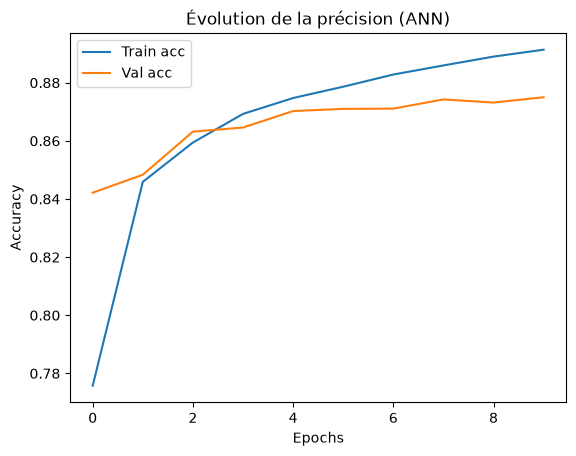

In [7]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

Questions:
1- Pourquoi utilise-t-on ReLU ?
ReLU introduit de la non-linéarité dans le réseau. Sans fonction d'activation non linéaire, empiler des couches entièrement linéaires ne permettrait pas de construire une fonction globalement plus expressive qu'une seule transformation linéaire. ReLU est également simple à calculer et facilite souvent l'entraînement des réseaux. (ReLU(x)=max(0,x))
2- Quelle est la différence entre accuracy et val_accuracy ?
accuracy mesure la proportion de prédictions correctes sur les données utilisées pour entraîner le modèle. val_accuracy mesure cette proportion sur les données de validation, qui ne servent pas à ajuster les poids. Leur comparaison permet d'évaluer la capacité du modèle à généraliser et de détecter un éventuel surapprentissage.
3- Que se passe-t-il si l’on augmente le nombre d’époques à 50 ? 
passer à 50 époques peut causer :
Un apprentissage plus précis : Le modèle a plus de temps pour ajuster ses réglages et réduire ses erreurs, mais l'entraînement prend beaucoup plus de temps.
le surapprentissage : À force de voir et revoir les mêmes images en boucle, le modèle risque de les apprendre par cœur au lieu de comprendre la logique générale.

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8670 - loss: 0.3638
Précision sur le test set : 0.8669999837875366


{'sigmoid': 0.862333357334137, 'tanh': 0.8712499737739563, 'relu': 0.8773333430290222, 'LeakyReLU': 0.8765833377838135}


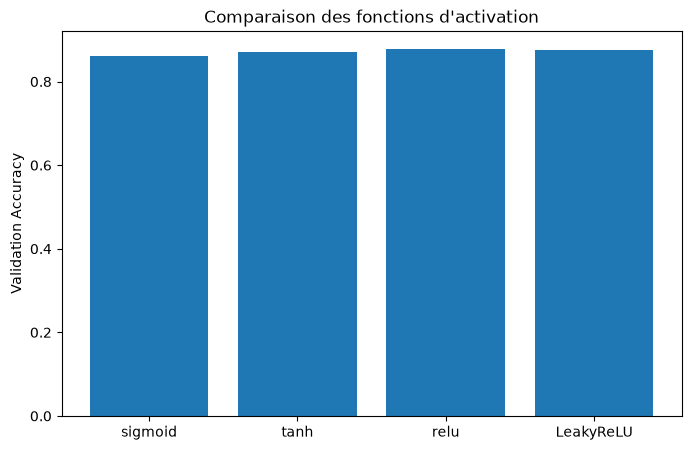

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, LeakyReLU
import matplotlib.pyplot as plt

activations = ['sigmoid', 'tanh', 'relu']
results = {}

# Tester Sigmoid, Tanh et ReLU
for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    model_act.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    h = model_act.fit(
        X_train, y_train_cat,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=0
    )

    results[act] = h.history['val_accuracy'][-1]

# Tester LeakyReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(negative_slope=0.1),
    Dense(64),
    LeakyReLU(negative_slope=0.1),
    Dense(10, activation='softmax')
])

model_leaky.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

h = model_leaky.fit(
    X_train, y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=0
)

results['LeakyReLU'] = h.history['val_accuracy'][-1]

# Afficher les résultats
print(results)

plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()


Questions:
1- la fonction d'activation donnant le meilleur résultat est :ReLU avec un pourcentage de 87,87% de prédictions correctes sur les données de validation
2- Pourquoi Sigmoid et Tanh sont-elles moins utilisées dans les couches cachées ?
Pour de grandes valeurs positives ou négatives, les dérivées des ces fonctions deviennent très faible. Pendant la rétropropagation, les gradients peuvent alors devenir très petits, ce qui ralentit l'apprentissage des premières couches.
ReLU évite cette saturation du côté positif et est généralement plus simple à calculer. Cela explique pourquoi elle est très utilisée dans les réseaux profonds.
3 — À quoi sert LeakyReLU ?
ReLU renvoie zéro pour toutes les entrées négatives. Un neurone peut ainsi cesser d'apprendre si ses sorties restent dans cette zone : c'est le problème du neurone mort (dying ReLU).
LeakyReLU conserve une petite pente pour les valeurs négatives. Avec une pente de 0,1 :
f(x)=x si x>=0 et 0.1x si x<0
Cela permet au gradient de rester non nul du côté négatif et peut aider certains neurones à continuer à apprendre.

Etape 5:
Pourquoi changer de réseau ?
Jusqu'ici, l'ANN utilisait Flatten() pour transformer chaque image de 28 × 28 pixels en un vecteur de 784 nombres.
Le problème est que cette opération ne conserve pas explicitement la structure spatiale de l'image pour les couches suivantes. Par exemple, deux pixels voisins peuvent représenter une partie importante du contour d'une chaussure, mais un réseau dense ne dispose pas d'un mécanisme spécifique pour exploiter les voisinages.
Le CNN (Convolutional Neural Network) est conçu pour mieux traiter ce type de données.

In [10]:

X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("Train CNN :", X_train_cnn.shape)
print("Test CNN :", X_test_cnn.shape)

Train CNN : (60000, 28, 28, 1)
Test CNN : (10000, 28, 28, 1)


In [11]:

from tensorflow.keras.layers import Conv2D, MaxPooling2D

cnn = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - accuracy: 0.7719 - loss: 0.6251 - val_accuracy: 0.8542 - val_loss: 0.4108
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.8562 - loss: 0.4031 - val_accuracy: 0.8723 - val_loss: 0.3548
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.8715 - loss: 0.3527 - val_accuracy: 0.8789 - val_loss: 0.3240
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.8816 - loss: 0.3246 - val_accuracy: 0.8876 - val_loss: 0.3034
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.8904 - loss: 0.2990 - val_accuracy: 0.8900 - val_loss: 0.2924
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.8955 - loss: 0.2829 - val_accuracy: 0.8937 - val_loss: 0.2846
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.9013 - loss: 0.2664 - val_accuracy: 0.8972 - val_loss: 0.2730
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.9075 - loss: 0.2499 - 

In [13]:
test_loss_cnn, test_acc_cnn = cnn.evaluate(
    X_test_cnn, y_test_cat
)

print("Précision CNN sur test set :", test_acc_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8996 - loss: 0.2688
Précision CNN sur test set : 0.8996000289916992


In [14]:
print(f"Précision ANN : {test_acc:.4f}")
print(f"Précision CNN : {test_acc_cnn:.4f}")

Précision ANN : 0.8670
Précision CNN : 0.8996


Questions
1 — Quelle est la différence entre un ANN et un CNN ?
L'ANN classique utilise des couches denses qui combinent les valeurs des pixels après leur aplatissement. Le CNN utilise en plus des couches de convolution et de pooling qui exploitent les relations spatiales entre les pixels pour extraire des caractéristiques des images.
2 — Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?
Le CNN apprend des caractéristiques locales, telles que les contours et les textures, puis les combine pour reconnaître des motifs plus complexes. Ses filtres sont partagés sur différentes zones de l'image, ce qui permet généralement d'apprendre des caractéristiques visuelles de manière plus efficace qu'un ANN dense classique.Cependant, un CNN ne garantit pas toujours de meilleurs résultats : les performances dépendent de l'architecture, des paramètres d'entraînement et des données.
Ici la précision du CNN est plus élevé.
3 — Quel est le rôle des couches de pooling ?
Les couches de pooling réduisent la taille spatiale des cartes de caractéristiques en conservant les informations les plus importantes. Cela réduit le nombre de calculs dans les couches suivantes et peut rendre le modèle moins sensible à de petits déplacements des motifs dans l'image.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


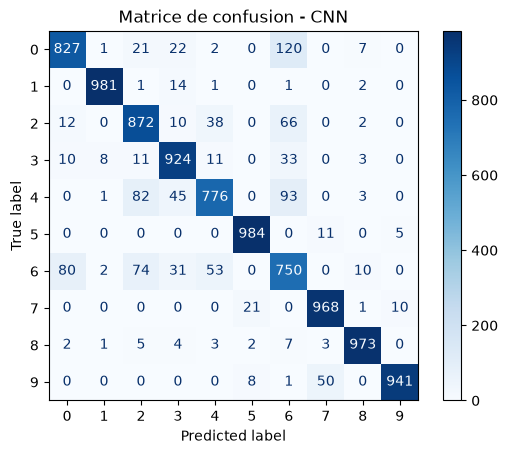

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Prédictions du CNN sur les images de test
y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

# Affichage de la matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Matrice de confusion - CNN")
plt.show()

Questions : 
1. Quelles classes sont le plus souvent confondues ? 
Les catégories les plus souvent confondues sont celles qui se ressemblent visuellement, notamment les T-shirts, les chemises et les pulls, les manteaux peuvent également être confondus avec certains hauts. Les confusions réellement observées doivent être identifiées à partir de la matrice de confusion du modèle entraîné.

In [18]:
class_names = [
    "T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
    "Sandale", "Chemise", "Basket", "Sac", "Bottine"
]

cm = confusion_matrix(y_test, y_pred)

# Ignorer la diagonale : elle correspond aux bonnes prédictions
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Trouver les confusions les plus fréquentes
for i in np.argsort(cm_errors.ravel())[::-1][:5]:
    vraie_classe, classe_predite = np.unravel_index(i, cm_errors.shape)
    print(
        class_names[vraie_classe],
        "prédit comme",
        class_names[classe_predite],
        ":",
        cm_errors[vraie_classe, classe_predite],
        "images"
    )

T-shirt prédit comme Chemise : 120 images
Manteau prédit comme Chemise : 93 images
Manteau prédit comme Pull : 82 images
Chemise prédit comme T-shirt : 80 images
Chemise prédit comme Pull : 74 images


2- Comment peut-on réduire ces erreurs de classification ? 
Plusieurs solutions sont possibles :
- Utiliser un CNN mieux adapté : ajouter ou modifier des couches de convolution pour extraire davantage de caractéristiques.
- Améliorer l'entraînement : ajuster le nombre d'époques, le taux d'apprentissage ou le nombre de filtres.
- Utiliser la Data Augmentation : présenter au réseau des versions légèrement transformées des images pour qu'il apprenne à mieux reconnaître les vêtements malgré de petites variations.
- Examiner les images mal classées : vérifier quelles caractéristiques rendent certaines catégories difficiles à distinguer.

In [20]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.8886 - loss: 0.3037 - val_accuracy: 0.9045 - val_loss: 0.2685
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 37s 78ms/step - accuracy: 0.8923 - loss: 0.2960 - val_accuracy: 0.9018 - val_loss: 0.2624
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 72ms/step - accuracy: 0.8947 - loss: 0.2878 - val_accuracy: 0.9054 - val_loss: 0.2600
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 76ms/step - accuracy: 0.8970 - loss: 0.2803 - val_accuracy: 0.9035 - val_loss: 0.2606
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 76ms/step - accuracy: 0.8981 - loss: 0.2776 - val_accuracy: 0.9082 - val_loss: 0.2484
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 76ms/step - accuracy: 0.9014 - loss: 0.2688 - val_accuracy: 0.9094 - val_loss: 0.2515
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 74ms/step - accuracy: 0.9018 - loss: 0.2667 - val_accuracy: 0.9097 - val_loss: 0.2575
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 32s 68ms/step - accuracy: 0.9061 - loss: 0.2564 - 

In [21]:
print(f"CNN avant augmentation : {test_acc_cnn:.4f}")

test_loss_aug, test_acc_aug = cnn.evaluate(
    X_test_cnn, y_test_cat
)

print(f"CNN après augmentation : {test_acc_aug:.4f}")

CNN avant augmentation : 0.8996
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9120 - loss: 0.2509
CNN après augmentation : 0.9120


Question 1 — Quel est l'intérêt de la Data Augmentation ?
La Data Augmentation permet d'augmenter artificiellement la diversité des images d'entraînement grâce à des transformations telles que la rotation, le zoom et le retournement horizontal. Elle aide le modèle à mieux généraliser à des images légèrement différentes de celles qu'il a vues et peut réduire le surapprentissage.
Elle ne garantit toutefois pas une amélioration : les transformations doivent rester adaptées aux images et aux catégories à reconnaître.
Question 2 — Quels types de transformations semblent les plus efficaces pour Fashion-MNIST ?
Les petites rotations et les légères variations de zoom sont des choix raisonnables pour ce dataset, car elles permettent au modèle de reconnaître les vêtements malgré de petites variations de position et de taille.
Le retournement horizontal peut également être utile pour certaines catégories, mais son intérêt dépend de la nature des images. Il faut comparer les résultats obtenus pour savoir quelles transformations améliorent réellement les performances.